<a href="https://colab.research.google.com/github/chawlaniharika23/Fraud_Detection_Research/blob/main/notebooks/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import sys
print("Python version:", sys.version)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import os

DATA_DIR = "/content/drive/MyDrive/fraud-detection-data"

print(os.listdir(DATA_DIR))

['ieee-fraud-detection.zip', 'archive.zip', 'paysim', 'ieee']


In [10]:
import os
import zipfile

DATA_DIR = "/content/drive/MyDrive/fraud-detection-data"

PAYSIM_DIR = os.path.join(DATA_DIR, "paysim")
IEEE_DIR = os.path.join(DATA_DIR, "ieee")

os.makedirs(PAYSIM_DIR, exist_ok=True)
os.makedirs(IEEE_DIR, exist_ok=True)

with zipfile.ZipFile(os.path.join(DATA_DIR, "archive.zip"), "r") as z:
    z.extractall(PAYSIM_DIR)

with zipfile.ZipFile(os.path.join(DATA_DIR, "ieee-fraud-detection.zip"), "r") as z:
    z.extractall(IEEE_DIR)


In [11]:
def list_files(folder):
    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            print(f"{file} — {os.path.getsize(path) / (1024**2):.2f} MB")

print("=== PaySim ===")
list_files(PAYSIM_DIR)

print("\n=== IEEE-CIS ===")
list_files(IEEE_DIR)

=== PaySim ===
PS_20174392719_1491204439457_log.csv — 470.67 MB

=== IEEE-CIS ===
sample_submission.csv — 5.80 MB
test_identity.csv — 24.60 MB
test_transaction.csv — 584.79 MB
train_identity.csv — 25.30 MB
train_transaction.csv — 651.69 MB


In [12]:
import pandas as pd
import os

paysim_files = []

for root, dirs, files in os.walk(PAYSIM_DIR):
    for file in files:
        if file.endswith(".csv"):
            paysim_files.append(os.path.join(root, file))

paysim_path = paysim_files[0]

paysim_sample = pd.read_csv(paysim_path, nrows=5)

print("Dataset preview:")
display(paysim_sample)

print("\nColumn names:")
print(paysim_sample.columns.tolist())

Dataset preview:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0



Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [13]:
import os
import pandas as pd

ieee_files = {}

for root, dirs, files in os.walk(IEEE_DIR):
    for file in files:
        if file.endswith(".csv"):
            ieee_files[file] = os.path.join(root, file)

for filename, path in sorted(ieee_files.items()):
    print(f"\n{'=' * 60}")
    print(f"File: {filename}")

    sample = pd.read_csv(path, nrows=3)
    print("Sample shape:", sample.shape)
    print("First 10 columns:", sample.columns.tolist()[:10])
    display(sample.head(2))


File: sample_submission.csv
Sample shape: (3, 2)
First 10 columns: ['TransactionID', 'isFraud']


,TransactionID,isFraud
0,3663549,0.5
1,3663550,0.5



File: test_identity.csv
Sample shape: (3, 41)
First 10 columns: ['TransactionID', 'id-01', 'id-02', 'id-03', 'id-04', 'id-05', 'id-06', 'id-07', 'id-08', 'id-09']


,TransactionID,id-01,id-02,id-03,id-04,id-05,id-06,id-07,id-08,id-09,...,id-31,id-32,id-33,id-34,id-35,id-36,id-37,id-38,DeviceType,DeviceInfo
0,3663586,-45.0,280290.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,...,chrome 67.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,MYA-L13 Build/HUAWEIMYA-L13
1,3663588,0.0,3579.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 67.0 for android,24.0,1280x720,match_status:2,T,F,T,T,mobile,LGLS676 Build/MXB48T



File: test_transaction.csv
Sample shape: (3, 393)
First 10 columns: ['TransactionID', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6']


,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,3663549,18403224,31.95,W,10409,111.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3663550,18403263,49.00,W,4272,111.0,150.0,visa,226.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



File: train_identity.csv
Sample shape: (3, 41)
First 10 columns: ['TransactionID', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09']


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device



File: train_transaction.csv
Sample shape: (3, 394)
First 10 columns: ['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5']


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
import pandas as pd
import os

paysim_path = os.path.join(
    PAYSIM_DIR,
    "PS_20174392719_1491204439457_log.csv"
)

paysim_df = pd.read_csv(paysim_path)

print("Dataset shape:", paysim_df.shape)
print("\nFirst 5 rows:")
display(paysim_df.head())

Dataset shape: (6362620, 11)

First 5 rows:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [15]:
fraud_counts = paysim_df["isFraud"].value_counts().sort_index()

print("Transaction counts:")
print(fraud_counts)

print("\nTransaction percentages:")
print((fraud_counts / len(paysim_df) * 100).round(4))

Transaction counts:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Transaction percentages:
isFraud
0    99.8709
1     0.1291
Name: count, dtype: float64


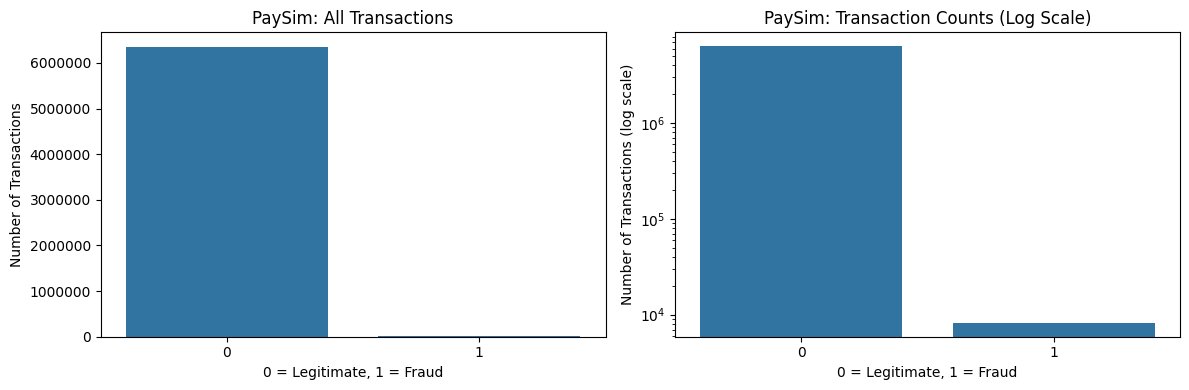

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

fraud_counts = paysim_df["isFraud"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Graph 1: Full scale
sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values,
    ax=axes[0]
)
axes[0].set_title("PaySim: All Transactions")
axes[0].set_xlabel("0 = Legitimate, 1 = Fraud")
axes[0].set_ylabel("Number of Transactions")
axes[0].ticklabel_format(axis="y", style="plain")
axes[0].tick_params(axis="y", rotation=0)

# Graph 2: Logarithmic scale
sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values,
    ax=axes[1]
)
axes[1].set_yscale("log")
axes[1].set_title("PaySim: Transaction Counts (Log Scale)")
axes[1].set_xlabel("0 = Legitimate, 1 = Fraud")
axes[1].set_ylabel("Number of Transactions (log scale)")

plt.tight_layout()
plt.show()

In [18]:
import os
import pandas as pd

ieee_train_path = os.path.join(IEEE_DIR, "train_transaction.csv")

ieee_train_df = pd.read_csv(ieee_train_path)

print("Dataset shape:", ieee_train_df.shape)
print("\nFirst 5 rows:")
display(ieee_train_df.head())

Dataset shape: (590540, 394)

First 5 rows:


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
ieee_fraud_counts = (
    ieee_train_df["isFraud"].value_counts().sort_index()
)

print("Transaction counts:")
print(ieee_fraud_counts)

print("\nTransaction percentages:")
print(
    (ieee_fraud_counts / len(ieee_train_df) * 100).round(4)
)

Transaction counts:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Transaction percentages:
isFraud
0    96.501
1     3.499
Name: count, dtype: float64


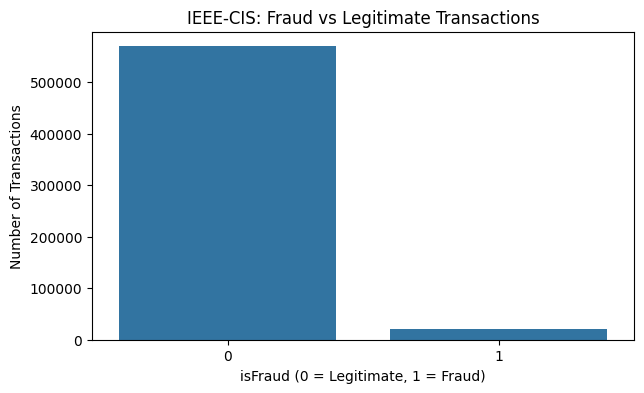

In [20]:
plt.figure(figsize=(7, 4))
sns.countplot(data=ieee_train_df, x="isFraud")
plt.title("IEEE-CIS: Fraud vs Legitimate Transactions")
plt.xlabel("isFraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [21]:
# Count missing values in each column
paysim_missing = paysim_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": paysim_missing,
    "Missing Percentage": (
        paysim_missing / len(paysim_df) * 100
    ).round(2)
})

print("Columns with missing values:")
display(missing_summary[missing_summary["Missing Values"] > 0])

print("Total missing values:", paysim_df.isnull().sum().sum())

Columns with missing values:


,Missing Values,Missing Percentage


Total missing values: 0


In [22]:
ieee_missing = ieee_train_df.isnull().sum()

ieee_missing_summary = pd.DataFrame({
    "Missing Values": ieee_missing,
    "Missing Percentage": (
        ieee_missing / len(ieee_train_df) * 100
    ).round(2)
})

ieee_missing_summary = ieee_missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

print("Total missing values:", ieee_missing.sum())
print("\nTop 20 columns with the most missing values:")

display(ieee_missing_summary.head(20))

Total missing values: 95566686

Top 20 columns with the most missing values:


,Missing Values,Missing Percentage
dist2,552913,93.63
D7,551623,93.41
D13,528588,89.51
D14,528353,89.47
D12,525823,89.04
D6,517353,87.61
D9,515614,87.31
D8,515614,87.31
V153,508595,86.12
V140,508595,86.12


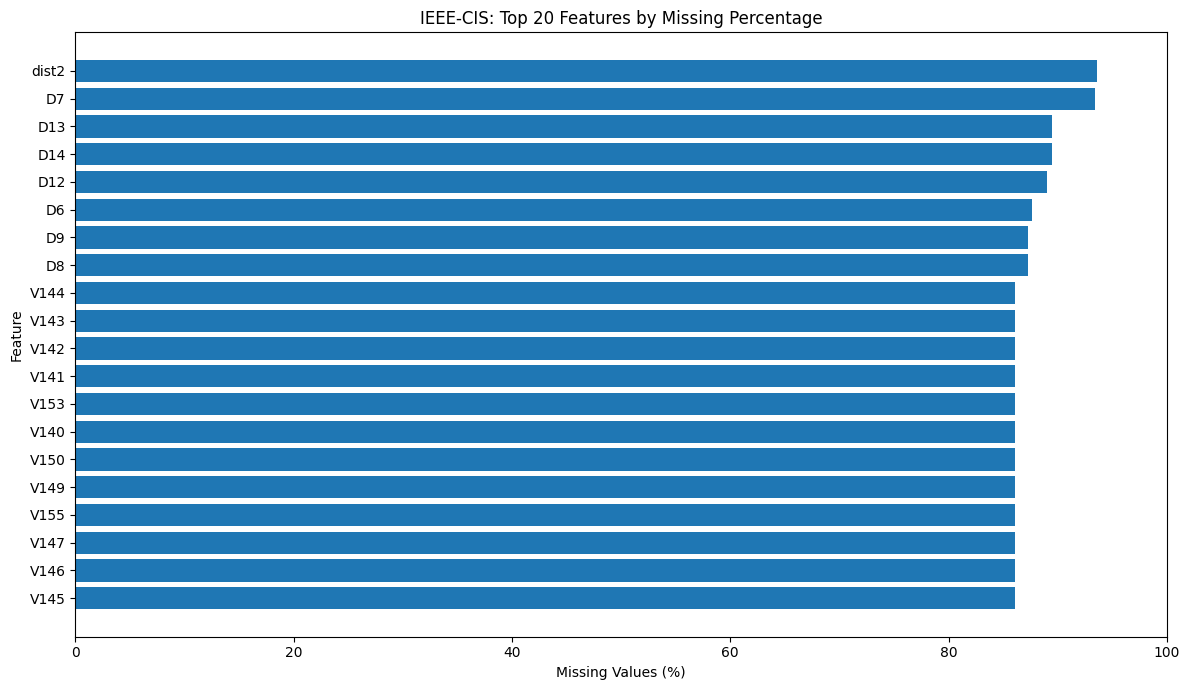

In [23]:
import matplotlib.pyplot as plt

top_missing = ieee_missing_summary.head(20).sort_values(
    "Missing Percentage"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_missing.index,
    top_missing["Missing Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("IEEE-CIS: Top 20 Features by Missing Percentage")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()